
<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/11_Lab_LagevineII_A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pylab as plt
import scipy.stats as stats
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from datasets import load_dataset
import json
from urllib.request import urlopen
from io import BytesIO
from pathlib import Path
from PIL import Image, ImageOps
import os
import keras
from keras import layers
import torch

Queremos entrenar una red neuonral que aprenda a estimar el score a partir de los datos. (en el caso anterior del lab10, lo conocíamos directamente a partir de, por ejemplo, una dsitribución gaussiana).

Partimos de generar una imagen simple $\mathbf{x}$ la cual se perturba agregando ruido gaussiano: $ \mathbf{y} = \mathbf{x} + \epsilon $. De modo que

$ p(\mathbf{y} | \mathbf{x} ) = \mathcal{N} (\mathbf{x}, \sigma^2 I) $

Con $\epsilon \sim  \mathcal{N}(0, \sigma^2 I)$. El score de la distribución de las imágenes perturbadas los definimos como
$ \mathbf{s}_{\theta} (\mathbf{y}, \sigma) \approx \nabla_y \log p (\mathbf{y}) $ . Con nuestra distribución gaussiana tenemos que

$$s_{obj} = \frac{\epsilon}{\sigma^2} $$

El campo de score actua como una fuerza efectiva que apunta hacia las regiones de mayor probabilidad , de modo que los píxeles ruidos puedan volver a su valor original.


Los parámetros se optimian minimizando la función de perdida


$$ L (\theta) = \frac{1}{2} \left < ||s_{theta}(y, \sigma) + \frac{\epsilon}{\sigma^2} ||^2 \right > $$


Y con la dinámica de Langevin, tenemos que

$$ x_{t+1} = x_t + \frac{\eta}{2} s(x_t) + \sqrt{\eta} z_t $$

el score guía el movimiento hacia regiones probables, mientras que el término aleatorio \(z_t\) permite explorar otras regiones.

### Generar imagen con ruido

Consideramos una imagen simple: matriz identidad de  $8 \times 8$. Para operar con ella se plana en un vector de 64 componentes.


In [ ]:
N = 8
Zr = stats.norm(loc=0, scale=1)
Z = Zr.rvs(size=N*N) # una muestra aleatoria por píxel

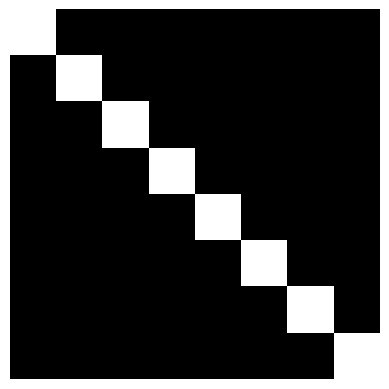

In [ ]:
X = np.eye(N)    # imagen diagonal blanca
x = X.flatten()  # Vector con N² píxeles

plt.imshow(x.reshape(N, N), cmap="gray", vmin=0, vmax=1)
plt.axis("off")
plt.show()

Se hace un escalamiento del ruido: $e = \sigma Z$.

In [ ]:
sigma=0.5
epsilon = sigma*Z
e = epsilon

### Algoritmo de denoinisng con score matching

ENTRADA: imágenes originales y niveles de ruido σ

Normalizar las imágenes
Separar datos de entrenamiento y evaluación
Inicializar los parámetros θ del modelo

REPETIR hasta completar el entrenamiento:
    Seleccionar un lote de imágenes originales x
    Seleccionar un nivel de ruido σ

    Generar ruido nuevo: e = σ · Normal(0, I)
    Construir imágenes perturbadas: y = x + e

    Calcular el campo objetivo: S_objetivo = −e / σ²
    Predecir el campo: S_predicho = sθ(y, σ)

    Pérdida = ½ · promedio(||S_predicho − S_objetivo||²)
    Actualizar θ usando el gradiente de la pérdida

Evaluar el modelo con los datos reservados
SALIDA: campo aprendido sθ(y, σ)

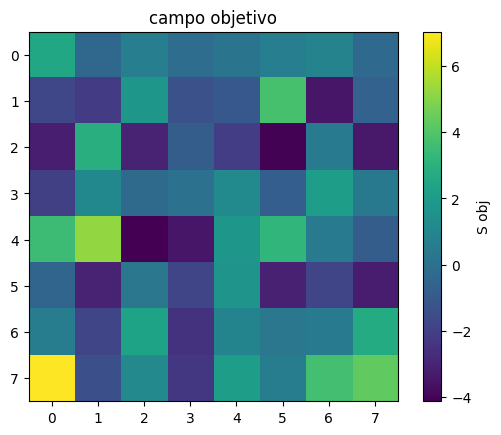

In [ ]:
# Ruido gaussiano - campo objeitvo
Sobjetivo = -e/sigma**2
plt.imshow(Sobjetivo.reshape(N, N))
plt.title("campo objetivo")
plt.colorbar(label="S obj")
plt.show()

para cada píxel, su intensidad indica hacia donde debe mvoerse para volver a su valor sin perturbar.

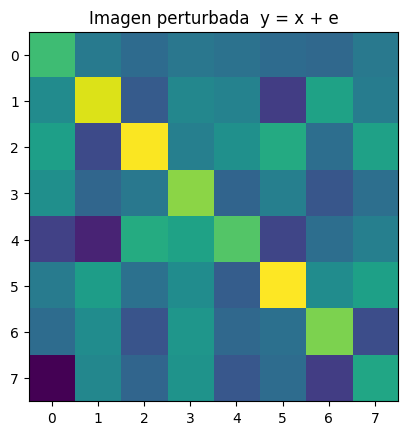

In [ ]:
xp = x + e*sigma
plt.imshow(xp.reshape(8,8))
plt.title("Imagen perturbada  y = x + e")
plt.show()

### Entrenamiento del modelo

Se repite el modelo de denosing muchas veces, la idea es la siguiente:

1. genera ruido $ \mathbf{e} = \sigma Z$
2. Perturbar la imágen: $\mathbf{y} = \mathbf{x} + \mathbf{e}$

3. Calcular el campo predicho por el modelo: $\mathbf{S}_{predicho} = A \mathbf{y} + \mathbf{B}$

4. Comparar con el campo objetivo $\mathbf{S}_{objetivo} = \mathbf{e} / \sigma^2$ a través de la función de perdida

$$ L = \frac{1}{2} \left < ||\mathbf{S}_{predicho} - \mathbf{S}_{objetivo} ||^2 \right>

In [ ]:
# Construir algoritmo

sigma= 2
#epsilon = sigma*Z
#e = epsilon

A = 0.0
B = 0.0
AlphaA = 0.5
AlphaB = 5.0
rng = np.random.default_rng(42)

for i in range(0, 50000):

    e = rng.normal(loc=0, scale=sigma, size=x.shape)
    xp = x + e
    Z = A*xp + B

    # campo obejetivo
    Sobjetivo = -e/sigma**2
    Spredicho = Z.copy() # score predicho

    error = (Spredicho - Sobjetivo )
    loss = 0.5 * np.mean(error**2)

    A = A - AlphaA * np.mean(error * xp)
    B = B - AlphaB * error/x.size

print("perdida final:", loss)
print("-1/σ² = ", - 1/sigma**2,"," " Predicho", A)

perdida final: 9.155876644132196e-18
-1/σ² =  -0.25 , Predicho -0.25000000087281626


In [ ]:
#Y = xp + sigma**2 * Spredicho
#plt.imshow(Y.reshape(8, 8))

ENTRADA: imagen perturbada y, nivel de ruido σ,
         campo aprendido sθ

Calcular el campo: S = sθ(y, σ)

Estimar la imagen limpia:
    x_estimada = y + σ² · S

Si conocemos la imagen original:
    Comparar la estimación con ella
    Calcular el error de recuperación

SALIDA: imagen limpia estimada

In [ ]:
rng_prueba = np.random.default_rng(123)

e_prueba = rng_prueba.normal(0, sigma, size=x.shape)
x_prueba = x + e_prueba

# 2. Evaluar el campo aprendido.
S_prueba = A * x_prueba + B

In [ ]:
# 3. Recuperar la imagen usando ese campo.
x_recuperado = x_prueba + sigma**2 * S_prueba

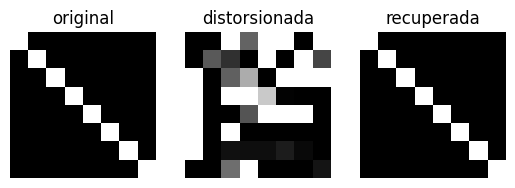

In [ ]:
plt.subplot(1, 3, 1)
plt.imshow(x.reshape(N, N), cmap="gray", vmin=0, vmax=1)
plt.title("original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(x_prueba.reshape(8,8), cmap="gray", vmin=0, vmax=1)
plt.title("distorsionada")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(x_recuperado.reshape(8,8), cmap="gray", vmin=0, vmax=1)
plt.title("recuperada")
plt.axis("off")

plt.show()

### Recuperación con ruido nuevo
Se pruea con un ruido que el modelo no vio durante el entrenamiento.

MSE con ruido:   3.453027835372964
MSE recuperada:  2.3492311654847175e-16
¿Recuperó x? True


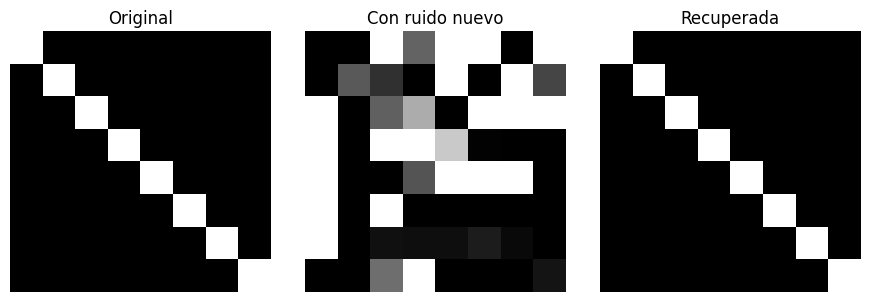

In [ ]:
# Prueba con ruido nuevo
rng_prueba = np.random.default_rng(123)    # Semilla distinta a la del entrenamiento

# 1. añadir ruido
e_prueba = rng_prueba.normal(0, sigma, size=x.shape)
y_prueba = x + e_prueba

# 2. Evaluar el campo con A y B ya entrenados (no se actualizan)
S_prueba = A * y_prueba + B

# 3. Recuperar la imagen
x_recuperada = y_prueba + sigma**2 * S_prueba

# 4. Medir el error
print("MSE con ruido:  ", np.mean((y_prueba - x)**2))      # ≈ σ²
print("MSE recuperada: ", np.mean((x_recuperada - x)**2))  # ≈ 0
print("¿Recuperó x?", np.allclose(x_recuperada, x, atol=1e-3))

# 5. Visualizar
fig, ejes = plt.subplots(1, 3, figsize=(9, 3))
for eje, (img, titulo) in zip(ejes, [(x, "Original"), (y_prueba, "Con ruido nuevo"), (x_recuperada, "Recuperada")]):
    eje.imshow(img.reshape(N, N), cmap="gray", vmin=0, vmax=1)
    eje.set_title(titulo)
    eje.axis("off")
plt.tight_layout()
plt.show()

### Dinámica de  Langevine

Ahora se busca generar una imagen partiendo del ruido sin usar la imagen original.

ENTRADA: campo aprendido, niveles σ de mayor a menor,
         número de pasos K y constante pequeña c

Inicializar desde ruido:
    Y = μ + σ_max · Normal(0, I)
    μ es la media de las imágenes de entrenamiento

PARA cada nivel σ, desde σ_max hasta σ_min:
    Elegir el paso: h = c · σ²

    REPETIR K veces:
        Calcular el campo: S = sθ(Y, σ)
        Generar ruido nuevo: Z = Normal(0, I)

        Actualizar mediante Langevin:
            Y = Y + h · S + √(2h) · Z

Opcionalmente aplicar la recuperación final:
    Y = Y + σ_min² · sθ(Y, σ_min)

SALIDA: imagen generada

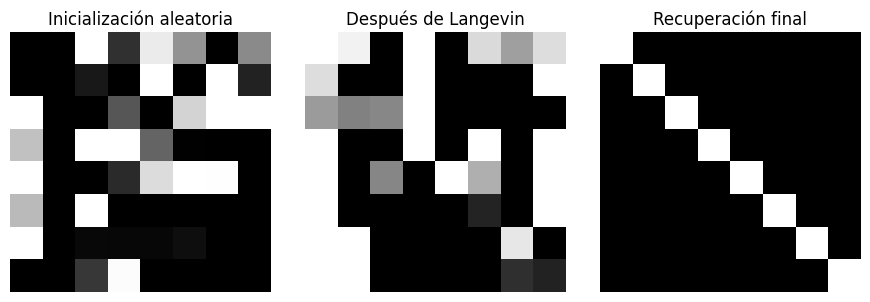

In [ ]:
rng_generacion = np.random.default_rng(123)

# Inicialización independiente de la imagen original.
Y = rng_generacion.normal(0, 1, size=x.shape)
Y_inicial = Y.copy()

dt = 0.001  # Para sigma = 0.1 y A cercano a -100.
n_pasos = 10000

# Aquí entra Langevin.
for paso in range(n_pasos):

    S = A * Y + B
    Z = rng_generacion.normal(size=Y.shape)
    Y = Y + dt * S + np.sqrt(2 * dt) * Z

# Recuperación final: es una operación distinta.
Y_recuperada = Y + sigma**2 * (A * Y + B)

fig, ejes = plt.subplots(1, 3, figsize=(9, 3))

comparaciones = [
    (Y_inicial, "Inicialización aleatoria"),
    (Y, "Después de Langevin"),
    (Y_recuperada, "Recuperación final")
]

for eje, (imagen, titulo) in zip(ejes, comparaciones):
    eje.imshow(
        np.clip(imagen.reshape(N, N), 0, 1),
        cmap="gray", vmin=0, vmax=1
    )
    eje.set_title(titulo)
    eje.axis("off")

plt.tight_layout()
plt.show()

DEspués de Langevin, la imagen no de distingue.  Se debe hacer la recuperación final para visualizar la imagen.

## Caso con más imagenes

La idea ahora es utilizar un cojunto de imagenes grande. Para eso usamos 1000 imagenes de perros dde la libredia datasets/cifar10. Queremos añadir ruido, calcular el campo score, entrenar un modelo lineal y usar la dinámica de Langevin al final.

In [ ]:
# cargar imagenes

datos = load_dataset(
    "uoft-cs/cifar10",
    split="train",
    streaming=True
)
perros = []

for ejemplo in datos:
    if ejemplo["label"] == 5:  # Perro
        perros.append(np.array(ejemplo["img"].convert("RGB")))

        if len(perros) % 25 == 0:
            print(f"Cargados: {len(perros)} perros")

        if len(perros) == 1000:
            break


README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

Cargados: 25 perros
Cargados: 50 perros
Cargados: 75 perros
Cargados: 100 perros
Cargados: 125 perros
Cargados: 150 perros
Cargados: 175 perros
Cargados: 200 perros
Cargados: 225 perros
Cargados: 250 perros
Cargados: 275 perros
Cargados: 300 perros
Cargados: 325 perros
Cargados: 350 perros
Cargados: 375 perros
Cargados: 400 perros
Cargados: 425 perros
Cargados: 450 perros
Cargados: 475 perros
Cargados: 500 perros
Cargados: 525 perros
Cargados: 550 perros
Cargados: 575 perros
Cargados: 600 perros
Cargados: 625 perros
Cargados: 650 perros
Cargados: 675 perros
Cargados: 700 perros
Cargados: 725 perros
Cargados: 750 perros
Cargados: 775 perros
Cargados: 800 perros
Cargados: 825 perros
Cargados: 850 perros
Cargados: 875 perros
Cargados: 900 perros
Cargados: 925 perros
Cargados: 950 perros
Cargados: 975 perros
Cargados: 1000 perros


Cada imagen es de tamaño $32 \times 32$ píxeles con $3$ canales (RGB). LLevamos las 1000 ímagenes a un solo objeto de dimensión $(1000, 32, 32, 3)$.

Forma: (1000, 32, 32, 3)


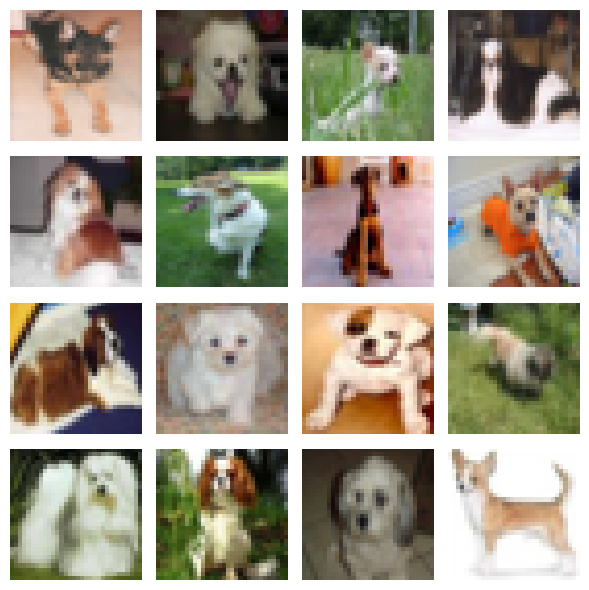

In [ ]:
# visualizar las primeras 16 imágenes

X_perros = np.stack(perros)
print("Forma:", X_perros.shape)

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for ax, imagen in zip(axes.ravel(), X_perros[:16]):
    ax.imshow(imagen)
    ax.axis("off")

plt.tight_layout()
plt.show()

### normalización

Los píxeles originales toman valores enteros en $[0, 255]$. Los llevamos al rango $[-1, 1]$ para que estén centrados en cero y poder aplicar el ruido de forma más consistente.

In [ ]:
X_entrenamiento = X_perros.astype(np.float32) / 127.5 - 1.0

### aplicar ruido

Similar al caso anterior, aplicamos un ruido gaussiano sobre cada pixel de cada imagen, esta vez sobre cada canal de color:

$$ \mathbf{\epsilon} \sim \mathcal{N}(0, \sigma^2, I) $$

Con \sigma = 0.3 . Así las imagenes perturbadas son $\mathbf{Y} = \mathbf{X} \mathbf{\epsilon}$. Y el campo objetivo: $\mathbf{S}_{objetivo} = -\mathbf{\epsilon}/\sigma^2$.

In [ ]:
# ruido y campo score

rng = np.random.default_rng(42)
sigma = 0.3

# Ruido independiente para cada imagen, píxel y canal
epsilon = rng.normal(
    loc=0,
    scale=sigma,
    size=X_entrenamiento.shape
).astype(np.float32)

X_ruidosas = X_entrenamiento + epsilon

# Campo objetivo para entrenar
S_objetivo = -epsilon / sigma**2

print("Imágenes limpias:", X_entrenamiento.shape)
print("Imágenes ruidosas:", X_ruidosas.shape)
print("Score objetivo:", S_objetivo.shape)

Imágenes limpias: (1000, 32, 32, 3)
Imágenes ruidosas: (1000, 32, 32, 3)
Score objetivo: (1000, 32, 32, 3)


### Visualización

Para la primera imagen, se separan sus 3 canales para visualizar la imagen original, el ruido, y la imagen con ruido.

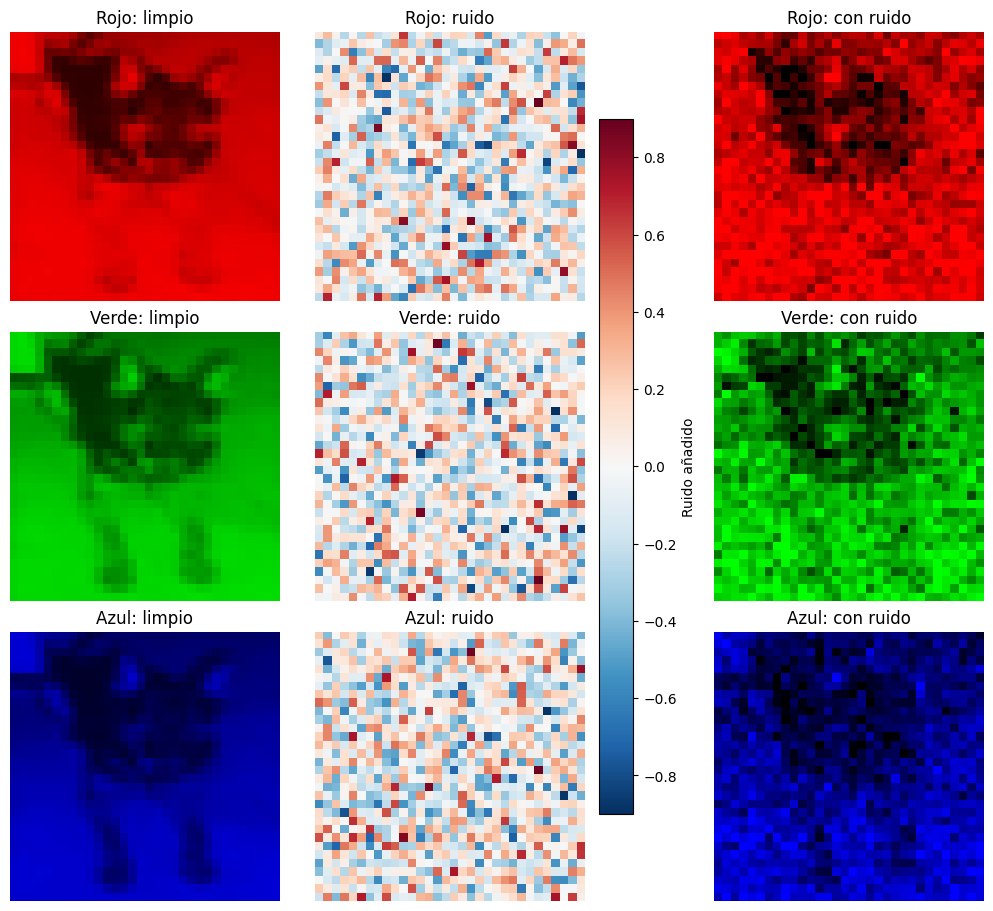

In [ ]:
i = 0
limpia = np.clip((X_entrenamiento[i] + 1) / 2, 0, 1)
ruidosa = np.clip((X_ruidosas[i] + 1) / 2, 0, 1)

nombres = ["Rojo", "Verde", "Azul"]

fig, axes = plt.subplots(
    3, 3, figsize=(10, 9), constrained_layout=True
)

for canal, nombre in enumerate(nombres):

    # Mostrar únicamente este canal en su color
    limpia_canal = np.zeros_like(limpia)
    limpia_canal[:, :, canal] = limpia[:, :, canal]

    ruidosa_canal = np.zeros_like(ruidosa)
    ruidosa_canal[:, :, canal] = ruidosa[:, :, canal]

    axes[canal, 0].imshow(limpia_canal)
    axes[canal, 0].set_title(f"{nombre}: limpio")

    im = axes[canal, 1].imshow(
        epsilon[i, :, :, canal],
        cmap="RdBu_r",
        vmin=-3 * sigma,
        vmax=3 * sigma
    )
    axes[canal, 1].set_title(f"{nombre}: ruido")

    axes[canal, 2].imshow(ruidosa_canal)
    axes[canal, 2].set_title(f"{nombre}: con ruido")

for ax in axes.ravel():
    ax.axis("off")

fig.colorbar(
    im,
    ax=axes[:, 1].tolist(),
    shrink=0.8,
    label="Ruido añadido"
)

plt.show()

### Imagen completa con ruido

Primera imagen con sus 3 canales de color + el ruido agregado.

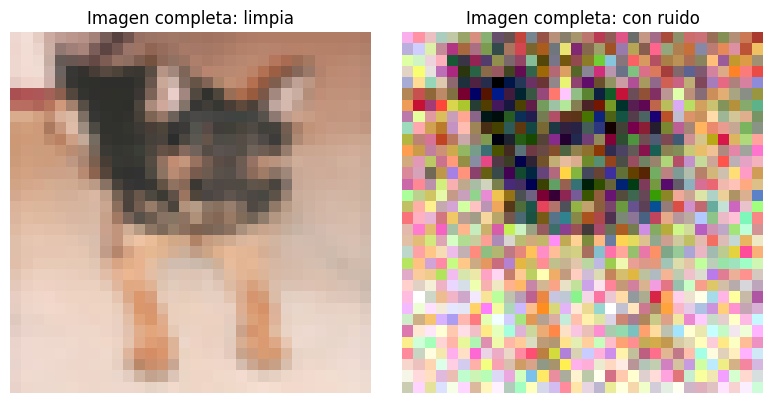

In [ ]:
i = 0
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(
    np.clip((X_entrenamiento[i] + 1) / 2, 0, 1)
)
axes[0].set_title("Imagen completa: limpia")
axes[1].imshow(
    np.clip((X_ruidosas[i] + 1) / 2, 0, 1)
)
axes[1].set_title("Imagen completa: con ruido")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Entrenamiento

Se utilizan las primeras 800 imagenes como datos de entrenamiento y las 200 restantes como datos de validación. Se utiliza el mismo modelo lineal

$$ \mathbf{S}_{predicho} = a \mathbf{Y} + \mathbf{B} $$


In [ ]:
# X_entrenamiento ya debe estar normalizado a [-1, 1]
corte = int(0.8 * len(X_entrenamiento))
datos = X_entrenamiento[:corte]
evaluacion = X_entrenamiento[corte:]

# Parámetros iniciales
a = 0.0
B = np.zeros_like(datos[0])

D = B.size  # Número de componentes: píxeles × canales

lr_a = 0.01
lr_B = lr_a * D  # Compensa el promedio sobre D componentes

En cada iteración, se toma al azar un lote de 32 imágenes del conjunto de entrenamiento. Se genera el ruido , se calcula el campo objetivo y campo predicho y  función de coste y sus gradientes para la actualización de los parámetros.

Paso 200: pérdida = 4.3932
Paso 400: pérdida = 4.0584
Paso 600: pérdida = 4.0082
Paso 800: pérdida = 4.1237
Paso 1000: pérdida = 3.9600
Paso 1200: pérdida = 4.0454
Paso 1400: pérdida = 4.1441
Paso 1600: pérdida = 4.0803
Paso 1800: pérdida = 4.2598
Paso 2000: pérdida = 3.9349
a aprendido: -3.0381432


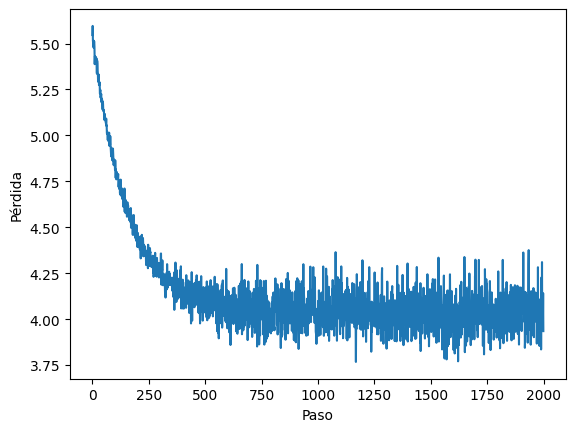

In [ ]:
n_pasos = 2000
historia = []
for paso in range(n_pasos):
    # Seleccionar un grupo de imágenes
    indices = rng.integers(0, len(datos), size=32)
    X = datos[indices]
    # Agregar ruido nuevo
    epsilon = rng.normal(0, sigma, size=X.shape).astype(np.float32)
    Y = X + epsilon
    # Score objetivo y score predicho
    S_objetivo = -epsilon / sigma**2

    S_predicho = a * Y + B



    error = S_predicho - S_objetivo
    loss = 0.5 * np.mean(error**2)
    # Gradientes de esa pérdida
    grad_a = np.mean(error * Y)
    grad_B = np.mean(error, axis=0) / D

    # Actualizar los parámetros
    a -= lr_a * grad_a
    B -= lr_B * grad_B

    historia.append(loss)

    if (paso + 1) % 200 == 0:
        print(f"Paso {paso + 1}: pérdida = {loss:.4f}")

print("a aprendido:", a)

plt.plot(historia)
plt.xlabel("Paso")
plt.ylabel("Pérdida")
plt.show()

La perdida inicial coincide con el valor teórico de $\frac{1}{2 \sigma^2} = 5.6$. La perdida después de 500 pasos se estabilizada al rededor de 4.0 , pero con oscilaciones significativas, pues el modelo lineal solo aprende el perro promedio.

### Evaluación

Ahora se toma un imagen del conjunto de test, se le añade ruido y se hace su recuperación como  $\mathbf{X} = \mathbf{Y} +  \sigma^2(a\mathbf{Y} + \mathbf{B})$.  

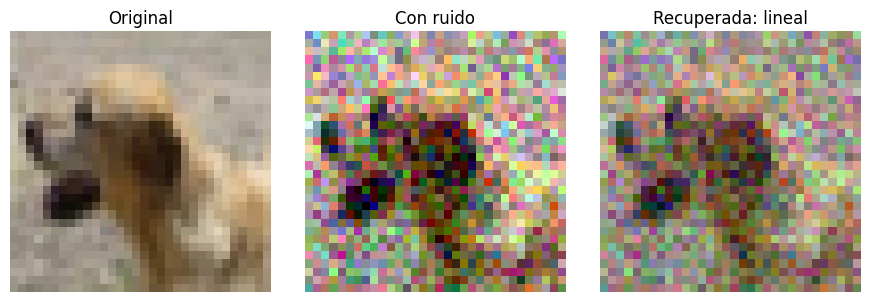

MSE con ruido: 0.0881564
MSE recuperada: 0.05862242


In [ ]:
X = evaluacion[4]

epsilon = rng.normal(
    0, sigma, size=X.shape
).astype(np.float32)

Y = X + epsilon

S_predicho = a * Y + B
X_recuperada = Y + sigma**2 * S_predicho

fig, axes = plt.subplots(1, 3, figsize=(9, 3))

imagenes = [X, Y, X_recuperada]
titulos = ["Original", "Con ruido", "Recuperada: lineal"]

for ax, imagen, titulo in zip(axes, imagenes, titulos):
    ax.imshow(np.clip((imagen + 1) / 2, 0, 1))
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("MSE con ruido:", np.mean((Y - X)**2))
print("MSE recuperada:", np.mean((X_recuperada - X)**2))

### Generación con Langevin

Generamos 4 imagenes de ruido puro. En una evoluciónde 100 pasos,aplicamos la dinámica de Lagevin

$ Y_{n+1} = Y_n + \Delta t S + \sqrt{2 \Delta t} Z_n $

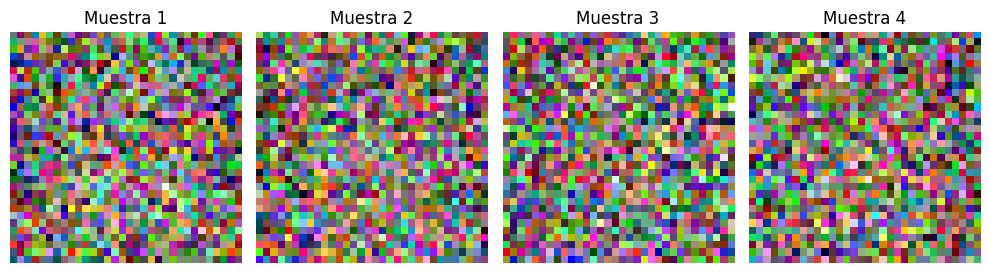

In [ ]:
rng = np.random.default_rng(123)

if a >= 0:
    raise ValueError("Necesitamos a < 0 para tener una distribución estable.")

# Cuatro imágenes inicializadas con ruido puro
Y = rng.normal(size=(4,) + B.shape).astype(np.float32)

dt = 0.05 / abs(a)  # Paso pequeño respecto a la escala del campo

for paso in range(1000):
    S = a * Y + B
    Z = rng.normal(size=Y.shape)
    Y = Y + dt * S + np.sqrt(2 * dt) * Z

fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for i, ax in enumerate(axes):
    ax.imshow(np.clip((Y[i] + 1) / 2, 0, 1))
    ax.set_title(f"Muestra {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
rng = np.random.default_rng(123)

if a >= 0:
    raise ValueError("Necesitamos a < 0.")

n_muestras = 200

Y = rng.normal(
    size=(n_muestras,) + B.shape
).astype(np.float32)

dt = 0.05 / abs(a)

for paso in range(1000):
    S = a * Y + B
    Z = rng.normal(size=Y.shape).astype(np.float32)

    Y = Y + dt * S + np.sqrt(2 * dt) * Z
# Promedio de las muestras, sin recortar sus valores
promedio = Y.mean(axis=0)
# Promedio esperado del modelo lineal
media_modelo = -B / a

### Lagenvin con muchas muestras

Aquí se generan 200 imagenes y se calculael promedio y la media del modelo:

$\Y_{prom} = \frac{1}{200} \sum_{j=1}^{200} Y^{(j)}$ y $\mu = -B/a$.

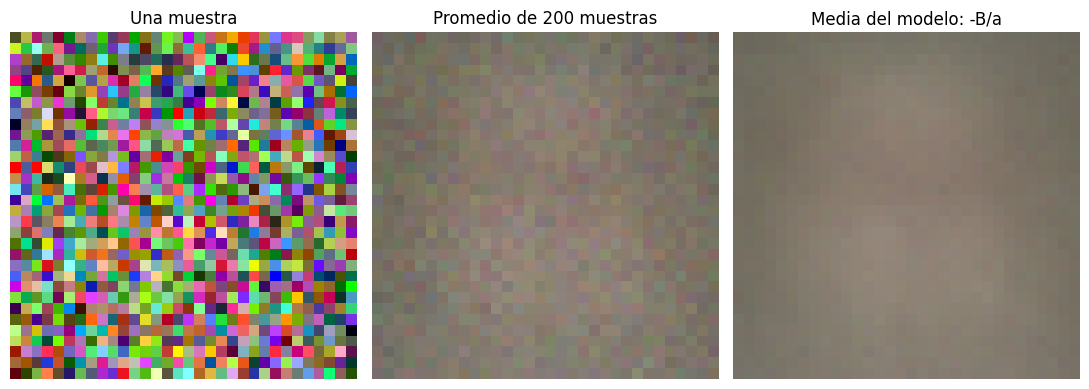

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4))

imagenes = [Y[0], promedio, media_modelo]
titulos = [
    "Una muestra",
    f"Promedio de {n_muestras} muestras",
    "Media del modelo: -B/a"
]

for ax, imagen, titulo in zip(axes, imagenes, titulos):
    ax.imshow(np.clip((imagen + 1) / 2, 0, 1))
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.show()

Aquí el modelo no genera imagenes reconocibles pues el ruido domina por completo. Al promediar entre las 200 realizaciones, las fluctuaciones aleatorias tienden a cancelarse entre sí y queda el valor medio de la distribución. En este caso se observa una mancha café, pues con el modelo lineal, el promedio de los perros es simplemente una mancha café, pues no sabe reconocer formas y la relación entre píxeles vecinos.

La tercera imagen muestrea la media del modelo, la cual se parece bastante al promedio pero con una mayor suavidad. Se observa en la parte central colores más claros, pues es aquí donde suelen estar localizados los perros.

El modelo de langevin en esencia funciona, pues $Y_{prom} \approx \mu$, sin embargo, no es suficiente para la generación correcta de imágenes.

In [ ]:
%pip install -q pillow numpy matplotlib

## Red neuronal convolucional

Dado que el modelo lineal no es suficiente, usamos en su lugar una red neuronal convolucional, de forma que pueda aprender patrones, bores, y relaciones entre píxeles vecinos. El método de entrenamiento el es mismo.

Aquí usamos $N= 100$ imgágenes de flores .

In [ ]:

N = 100  # Puedes empezar con 20 para descargar todavía menos.
TAMANO = 64

carpeta = Path("flores_64")
carpeta.mkdir(exist_ok=True)

url = (
    "https://datasets-server.huggingface.co/rows?"
    "dataset=nkirschi/oxford-flowers&config=default&split=train"
    f"&offset=0&length={N}"
)

# Consultar únicamente las imágenes solicitadas.
with urlopen(url, timeout=60) as respuesta:
    filas = json.load(respuesta)["rows"]

imagenes = []

for i, fila in enumerate(filas):
    archivo = carpeta / f"flor_{i:03d}.png"

    if not archivo.exists():
        with urlopen(fila["row"]["image"]["src"], timeout=60) as respuesta:
            imagen = Image.open(BytesIO(respuesta.read())).convert("RGB")

        imagen = ImageOps.fit(imagen, (TAMANO, TAMANO))
        imagen.save(archivo)

    with Image.open(archivo) as imagen:
        imagenes.append(np.array(imagen))

# Valores entre 0 y 1, listos para trabajar después con Keras.
imagenes = np.array(imagenes, dtype="float32") / 255.0
print("Forma:", imagenes.shape)


Forma: (100, 64, 64, 3)


Al igual que en el caso anterior, las imagenes se guardan en un vector de dimensión $(100, 64, 64, 3)$.

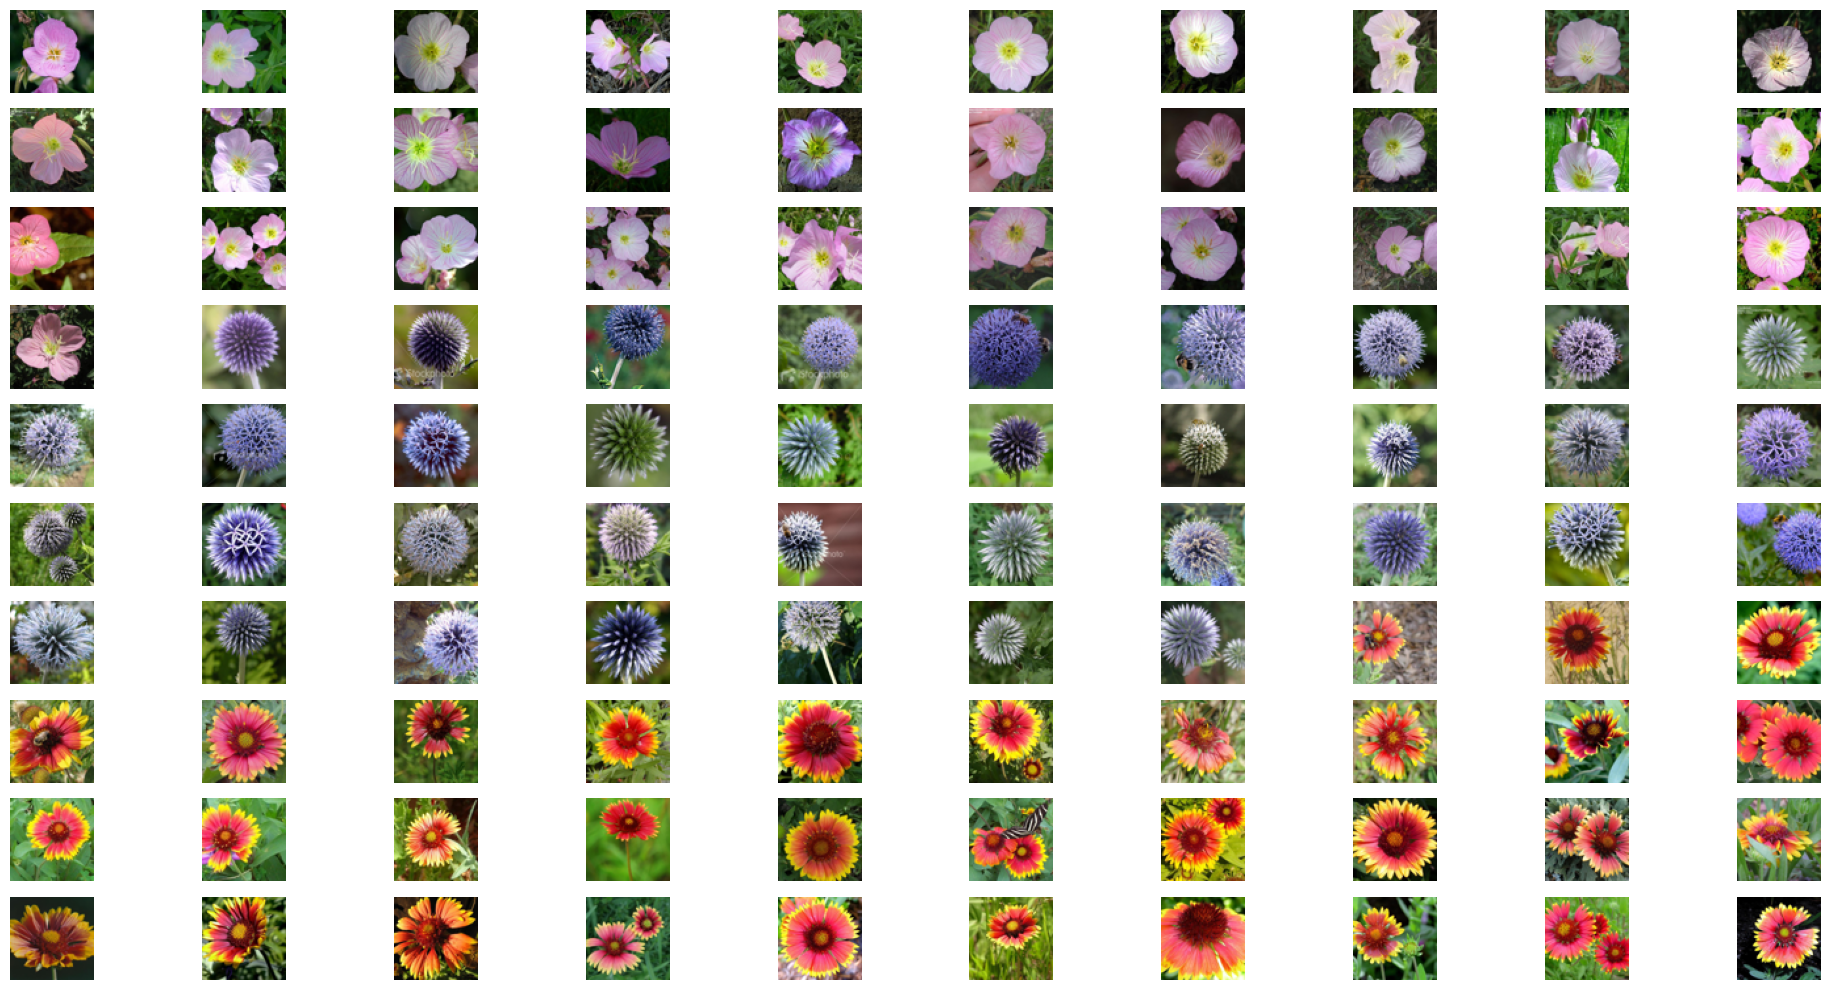

In [ ]:
# Visualizar algunas flores.
fig, ejes = plt.subplots(10, 10, figsize=(20, 10))
for eje, imagen in zip(ejes.flat, imagenes[:100]):
    eje.imshow(imagen)
    eje.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
np.shape(imagenes)

(100, 64, 64, 3)

### Separación de los datos

Se utiliza similarmente, una proporción 80/20 para los datos de entrenamiento y de test. Además nos aseguramos de que no haya algún orden específico entre ellas.

In [ ]:
rng = np.random.default_rng(42)

# 1. Barajar y separar las imágenes.
indices = rng.permutation(len(imagenes))
corte = int(0.8 * len(imagenes))

entrenamiento = imagenes[indices[:corte]]
test = imagenes[indices[corte:]]

print("Entrenamiento:", entrenamiento.shape)
print("Test:", test.shape)

# 2. Perturbar todos los píxeles y canales.
sigma = 0.20  # Intensidad del ruido; las imágenes están entre 0 y 1.

def perturbar(X, sigma):
    ruido = rng.normal(size=X.shape).astype("float32")
    return X + sigma * ruido, ruido

entrenamiento_perturbado, ruido_train = perturbar(entrenamiento, sigma)
test_perturbado, ruido_test = perturbar(test, sigma)

# 3. Comparar una imagen antes y después.
i = 0


Entrenamiento: (80, 64, 64, 3)
Test: (20, 64, 64, 3)


Añadimos ruido a la imagen. En este caso, la función perturbar, devuelve la imágen con ruido, y el ruido que estámos aplicando sobre la imágen.

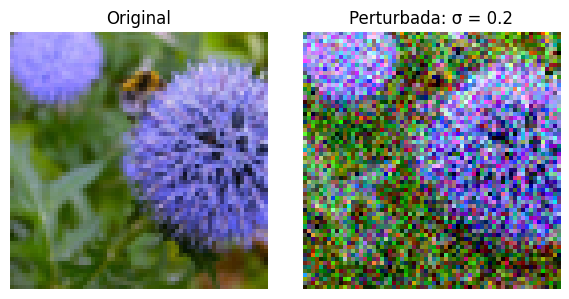

In [ ]:

fig, ejes = plt.subplots(1, 2, figsize=(6, 3))

ejes[0].imshow(entrenamiento[i])
ejes[0].set_title("Original")

# Recortamos a [0, 1] únicamente para visualizar.
ejes[1].imshow(np.clip(entrenamiento_perturbado[i], 0, 1))
ejes[1].set_title(f"Perturbada: σ = {sigma}")

for eje in ejes:
    eje.axis("off")

plt.tight_layout()
plt.show()

### Construción de la red

La red recibe la imágen con ruido y devuelve una predicción del ruido.

In [ ]:
os.environ["KERAS_BACKEND"] = "torch"


keras.utils.set_random_seed(42)

modelo = keras.Sequential([
    keras.Input(shape=entrenamiento.shape[1:]),

    layers.Conv2D(
        32, kernel_size=3, padding="same", activation="relu"
    ),
    layers.Conv2D(
        32, kernel_size=3, padding="same", activation="relu"
    ),

    # Predecir el ruido de los tres canales RGB.
    layers.Conv2D(3, kernel_size=3, padding="same")
])

modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse"
)

modelo.summary()

print("Entrada:", modelo.input_shape)
print("Salida:", modelo.output_shape)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,011 (43.01 KB)

 Trainable params: 11,011 (43.01 KB)

 Non-trainable params: 0 (0.00 B)

Entrada: (None, 64, 64, 3)
Salida: (None, 64, 64, 3)


### Entrnamiento de la red

Se entrenada durante 20 épocas. En cada una se hace lo siguiente:

1. Se añade ruido a los datos de entrenanmiento. En cada época se genera ruido nuevo para que la red no memorice.

$$ \mathbf{Y} = \mathbf{X} + \sigma \mathbf{Z} $$.

2. El modelo aprende a predecir $\mathbf{Z}$.

3. Se evlua sobre el cojunto de test y se cálcula el error cuadrático medio.

In [ ]:
sigma = 0.15
n_epocas = 20

perdidas_train = []
perdidas_test = []

# El test mantiene el mismo ruido durante toda la evaluación.
test_perturbado, ruido_test = perturbar(test, sigma)

for epoca in range(n_epocas):
    # Entrenamiento con ruido nuevo.
    entradas, ruido_real = perturbar(entrenamiento, sigma)

    historia = modelo.fit(
        entradas,
        ruido_real,
        epochs=1,
        batch_size=8,
        shuffle=True,
        verbose=0
    )

    mse_train = historia.history["loss"][0]

    # Evaluación: los pesos permanecen fijos.
    mse_test = modelo.evaluate(
        test_perturbado,
        ruido_test,
        batch_size=8,
        verbose=0
    )

    perdidas_train.append(mse_train)
    perdidas_test.append(mse_test)

    print(
        f"Época {epoca + 1:02d}/{n_epocas} | "
        f"Train: {mse_train:.4f} | Test: {mse_test:.4f}"
    )

# Graficar ambas curvas.
epocas = range(1, n_epocas + 1)


Época 01/20 | Train: 0.9557 | Test: 0.8968
Época 02/20 | Train: 0.8306 | Test: 0.7425
Época 03/20 | Train: 0.6712 | Test: 0.5873
Época 04/20 | Train: 0.5299 | Test: 0.4636
Época 05/20 | Train: 0.4164 | Test: 0.3641
Época 06/20 | Train: 0.3325 | Test: 0.3014
Época 07/20 | Train: 0.2838 | Test: 0.2618
Época 08/20 | Train: 0.2541 | Test: 0.2406
Época 09/20 | Train: 0.2349 | Test: 0.2270
Época 10/20 | Train: 0.2248 | Test: 0.2192
Época 11/20 | Train: 0.2192 | Test: 0.2113
Época 12/20 | Train: 0.2146 | Test: 0.2068
Época 13/20 | Train: 0.2096 | Test: 0.2040
Época 14/20 | Train: 0.2069 | Test: 0.2022
Época 15/20 | Train: 0.2069 | Test: 0.2006
Época 16/20 | Train: 0.2073 | Test: 0.1993
Época 17/20 | Train: 0.2048 | Test: 0.1989
Época 18/20 | Train: 0.2043 | Test: 0.1974
Época 19/20 | Train: 0.2028 | Test: 0.1967
Época 20/20 | Train: 0.2032 | Test: 0.1965


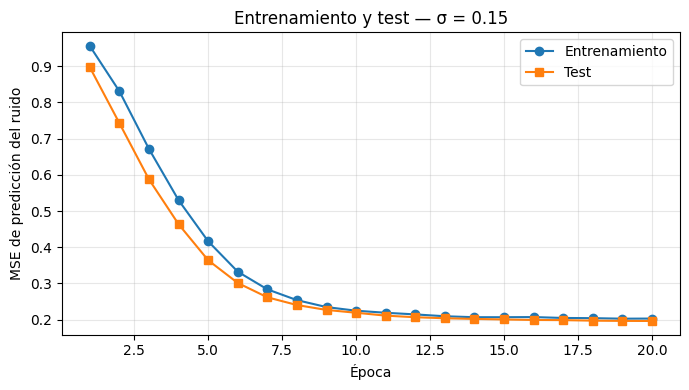

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(epocas, perdidas_train, "o-", label="Entrenamiento")
plt.plot(epocas, perdidas_test, "s-", label="Test")
plt.xlabel("Época")
plt.ylabel("MSE de predicción del ruido")
plt.title(f"Entrenamiento y test — σ = {sigma}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Recuperación de imagenes

Con el ruido predicho por la red $\hat{Z} = \text{red}_{\theta} (Y)$, se puede recuperar la imagen

$$ X_{recuperada} = Y - \sigma \hat{Z} $$.

MSE antes:   0.022501
MSE después: 0.004421


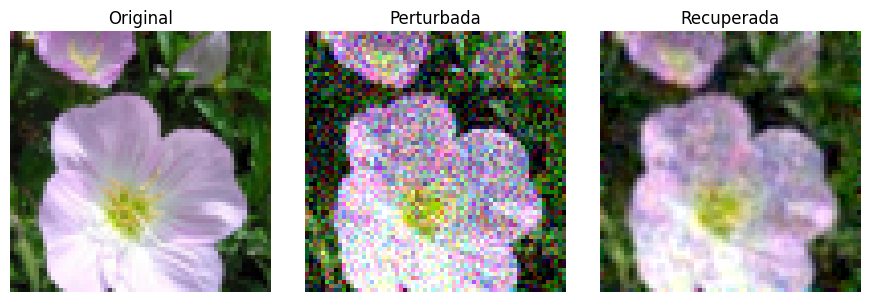

In [ ]:
# Predecir el ruido y restarlo.
ruido_predicho = modelo.predict(
    test_perturbado, batch_size=8, verbose=0
)

sigma=0.15
recuperadas = test_perturbado - sigma * ruido_predicho

# Comparar el error respecto a las imágenes originales.
mse_antes = np.mean((test_perturbado - test)**2)
mse_despues = np.mean((recuperadas - test)**2)

print(f"MSE antes:   {mse_antes:.6f}")
print(f"MSE después: {mse_despues:.6f}")

# Visualizar una flor.
i = 3
fig, ejes = plt.subplots(1, 3, figsize=(9, 3))

comparacion = [
    (test[i], "Original"),
    (test_perturbado[i], "Perturbada"),
    (recuperadas[i], "Recuperada")
]

for eje, (imagen, titulo) in zip(ejes, comparacion):
    eje.imshow(np.clip(imagen, 0, 1))  # Recorte solo para mostrar.
    eje.set_title(titulo)
    eje.axis("off")

plt.tight_layout()
plt.show()

### Generación de Imágenes

Se busca ahora crear 9 imágenes con el modelo, partiendo solmanete del ruido.
Al pasarle la imagen de ruido a la red, obtenemos una estimación de ese ruido. Con esto calculamos el campo de score para intentar mover cada píxel en la dirección que haya menos ruido. Finalmente, con la dinámica de Lagenvin obtenemos su evolución.

In [ ]:
n_imagenes = 9
n_pasos = 5000
rng_generacion = np.random.default_rng(123)

# Paso pequeño de Langevin.
h = np.float32(0.005 * sigma**2)
amplitud = np.float32(np.sqrt(2 * h))

# Inicialización independiente de las flores originales.
forma = tuple(modelo.input_shape[1:])
generadas = rng_generacion.uniform(
    0, 1, size=(n_imagenes, *forma)
).astype("float32")

# Guardar la evolución de la primera imagen.
evolucion = {0: generadas[0].copy()}
guardar_en = {50, 100, 250, n_pasos}

# Inferencia con tu backend Torch: los pesos permanecen fijos.
with torch.no_grad():
    for paso in range(1, n_pasos + 1):

        # La red predice epsilon, no sigma * epsilon.
        ruido_predicho = keras.ops.convert_to_numpy(
            modelo(generadas, training=False)
        )

        score = -ruido_predicho / sigma

        # Ruido nuevo para la dinámica de Langevin.
        z = rng_generacion.normal(
            size=generadas.shape
        ).astype("float32")

        generadas = generadas + h * score + amplitud * z

        # Mantener los valores sin recortar durante la dinámica.
        if paso in guardar_en:
            evolucion[paso] = generadas[0].copy()

        if paso % 100 == 0:
            if not np.isfinite(generadas).all():
                raise FloatingPointError(
                    "La dinámica diverge. Reduce el valor de h."
                )
            print(f"Paso {paso}/{n_pasos}")



Paso 100/5000
Paso 200/5000
Paso 300/5000
Paso 400/5000
Paso 500/5000
Paso 600/5000
Paso 700/5000
Paso 800/5000
Paso 900/5000
Paso 1000/5000
Paso 1100/5000
Paso 1200/5000
Paso 1300/5000
Paso 1400/5000
Paso 1500/5000
Paso 1600/5000
Paso 1700/5000
Paso 1800/5000
Paso 1900/5000
Paso 2000/5000
Paso 2100/5000
Paso 2200/5000
Paso 2300/5000
Paso 2400/5000
Paso 2500/5000
Paso 2600/5000
Paso 2700/5000
Paso 2800/5000
Paso 2900/5000
Paso 3000/5000
Paso 3100/5000
Paso 3200/5000
Paso 3300/5000
Paso 3400/5000
Paso 3500/5000
Paso 3600/5000
Paso 3700/5000
Paso 3800/5000
Paso 3900/5000
Paso 4000/5000
Paso 4100/5000
Paso 4200/5000
Paso 4300/5000
Paso 4400/5000
Paso 4500/5000
Paso 4600/5000
Paso 4700/5000
Paso 4800/5000
Paso 4900/5000
Paso 5000/5000


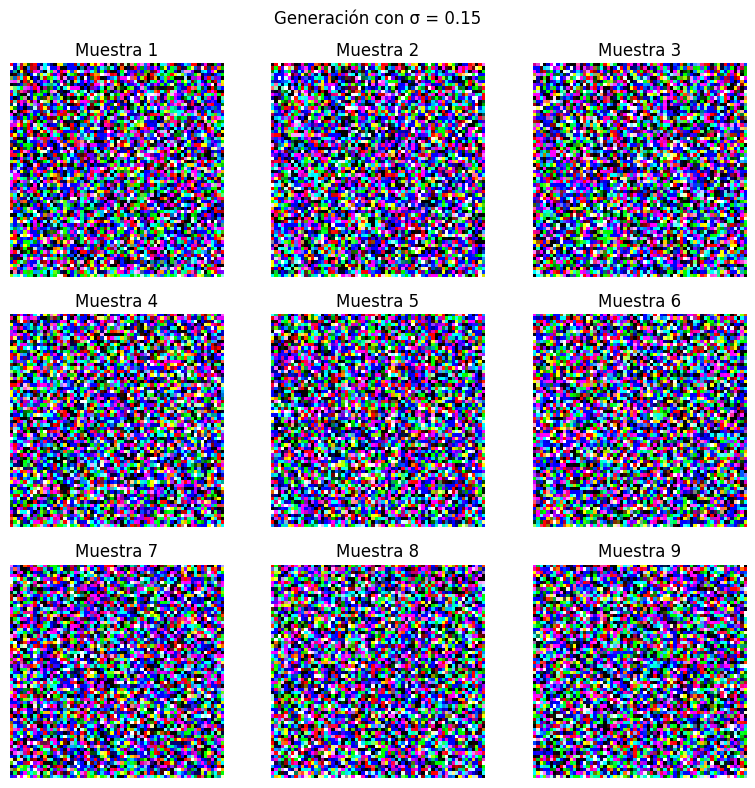

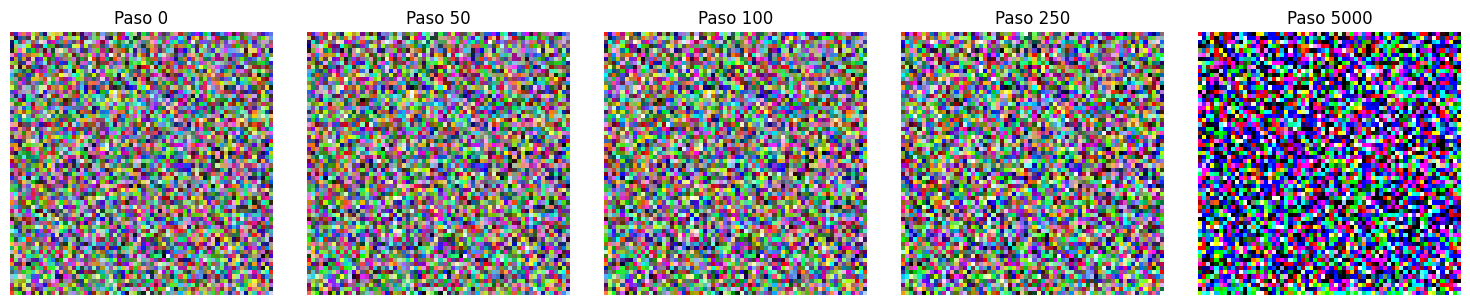

In [ ]:
# Mostrar las nueve imágenes finales.
fig, ejes = plt.subplots(3, 3, figsize=(8, 8))

for i, eje in enumerate(ejes.flat):
    eje.imshow(np.clip(generadas[i], 0, 1))
    eje.set_title(f"Muestra {i + 1}")
    eje.axis("off")

fig.suptitle(f"Generación con σ = {float(sigma):.2f}")
plt.tight_layout()
plt.show()

# Mostrar cómo evolucionó la primera imagen.
fig, ejes = plt.subplots(
    1, len(evolucion), figsize=(3 * len(evolucion), 3)
)

for eje, (paso, imagen) in zip(ejes, evolucion.items()):
    eje.imshow(np.clip(imagen, 0, 1))
    eje.set_title(f"Paso {paso}")
    eje.axis("off")

plt.tight_layout()
plt.show()


La generación de imágenes no funcionó. No se observan patrones reconocibles, solo colores saturados. Dadod que Langevin parte de imágenes puramente ruidosas, la red no es capaz de reconocerlo, y se queda solo en las imágenes que están cercanas a flores reales.

## Tarea-laboratorio: Implementar una red tipo Unet

La red convolucional anterior tenía dos problemas. Solo mira grupos pequeños de píxeles vecinos, así que no logra entender la forma completa de una flor. Además, solo aprendió a quitar un nivel de ruido, entonces cuando empezamos desde ruido puro no sabe hacia dónde mover la imagen.

La U-Net tiene forma de “U”:

Bajada: la imagen se va haciendo más pequeña (64 → 32 → 16 → 8). Así la red ve la imagen completa y aprende la forma general.
Subida: la imagen vuelve a crecer hasta su tamaño original.
Puentes (conexiones de salto): unen cada nivel de bajada con el de subida del mismo tamaño, para no perder los detalles finos.

Además, le decimos a la red cuánto ruido tiene la imagen (σ). Así una sola red aprende a limpiar desde imágenes casi irreconocibles hasta imágenes con muy poco ruido. Para generar, empezamos con mucho ruido y lo vamos bajando poco a poco. Primero aparece la forma general de la flor y luego los detalles.

### Construir la red

In [ ]:
sigmas = np.geomspace(1.0, 0.01, 10).astype("float32")

def bloque_simple(x, filtros):
    x = layers.Conv2D(filtros, 3, padding="same", activation="relu")(x)
    x = layers.Conv2D(filtros, 3, padding="same", activation="relu")(x)
    return x

def unet_simple(forma):
    entrada_img = keras.Input(shape=forma)        # (64, 64, 3)
    entrada_sigma = keras.Input(shape=(1,))       # log(σ)

    # Convertimos σ en una "capa" de 64x64 y la pegamos a la imagen
    mapa_sigma = layers.Reshape((1, 1, 1))(entrada_sigma)
    mapa_sigma = layers.UpSampling2D(size=forma[:2])(mapa_sigma)
    x = layers.Concatenate()([entrada_img, mapa_sigma])   # (64, 64, 4)

    # Bajada
    b1 = bloque_simple(x, 16)                       # 64x64
    x = layers.MaxPooling2D(2)(b1)
    b2 = bloque_simple(x, 32)                       # 32x32
    x = layers.MaxPooling2D(2)(b2)

    # Fondo
    x = bloque_simple(x, 64)                        # 16x16

    # Subida con puentes
    x = layers.UpSampling2D(2)(x)
    x = layers.Concatenate()([x, b2])
    x = bloque_simple(x, 32)                        # 32x32
    x = layers.UpSampling2D(2)(x)
    x = layers.Concatenate()([x, b1])
    x = bloque_simple(x, 16)                        # 64x64

    salida = layers.Conv2D(3, 1)(x)                 # ruido predicho (RGB)
    return keras.Model([entrada_img, entrada_sigma], salida)

keras.utils.set_random_seed(42)
unet = unet_simple(entrenamiento.shape[1:])
unet.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse")
unet.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_9       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_11          │ (None, 1, 1, 1)   │          0 │ input_layer_9[0]… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_8       │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_9     │ (None, 64, 64, 1) │          0 │ reshape_11[0][0]  │
│ (UpSampling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_10      │ (None, 64, 64, 4) │          0 │ input_layer_8[0]… │
│ (Concatenate)       │                   │            │ up_sampling2d_9[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_60 (Conv2D)  │ (None, 64, 64,    │        592 │ concatenate_10[0… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_61 (Conv2D)  │ (None, 64, 64,    │      2,320 │ conv2d_60[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 32, 32,    │          0 │ conv2d_61[0][0]   │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_62 (Conv2D)  │ (None, 32, 32,    │      4,640 │ max_pooling2d_4[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_63 (Conv2D)  │ (None, 32, 32,    │      9,248 │ conv2d_62[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 16, 16,    │          0 │ conv2d_63[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_64 (Conv2D)  │ (None, 16, 16,    │     18,496 │ max_pooling2d_5[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_65 (Conv2D)  │ (None, 16, 16,    │     36,928 │ conv2d_64[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_10    │ (None, 32, 32,    │          0 │ conv2d_65[0][0]   │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_11      │ (None, 32, 32,    │          0 │ up_sampling2d_10… │
│ (Concatenate)       │ 96)               │            │ conv2d_63[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_66 (Conv2D)  │ (None, 32, 32,    │     27,680 │ concatenate_11[0… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_67 (Conv2D)  │ (None, 32, 32,    │      9,248 │ conv2d_66[0][0] 

 Total params: 118,451 (462.70 KB)

 Trainable params: 118,451 (462.70 KB)

 Non-trainable params: 0 (0.00 B)

Época 01/50 | train 0.9976 | test 0.9752
Época 02/50 | train 0.9049 | test 0.8632
Época 03/50 | train 0.8058 | test 0.7956
Época 04/50 | train 0.7562 | test 0.7380
Época 05/50 | train 0.6624 | test 0.6866
Época 06/50 | train 0.6520 | test 0.6478
Época 07/50 | train 0.5925 | test 0.6168
Época 08/50 | train 0.5796 | test 0.5983
Época 09/50 | train 0.5439 | test 0.5832
Época 10/50 | train 0.5317 | test 0.5719
Época 11/50 | train 0.5029 | test 0.5579
Época 12/50 | train 0.5141 | test 0.5536
Época 13/50 | train 0.5105 | test 0.5478
Época 14/50 | train 0.4943 | test 0.5428
Época 15/50 | train 0.4907 | test 0.5477
Época 16/50 | train 0.4817 | test 0.5245
Época 17/50 | train 0.4868 | test 0.5204
Época 18/50 | train 0.4803 | test 0.5161
Época 19/50 | train 0.4733 | test 0.5100
Época 20/50 | train 0.4829 | test 0.5023
Época 21/50 | train 0.4560 | test 0.4963
Época 22/50 | train 0.4585 | test 0.4914
Época 23/50 | train 0.4397 | test 0.4831
Época 24/50 | train 0.4547 | test 0.4767
Época 25/50 | tr

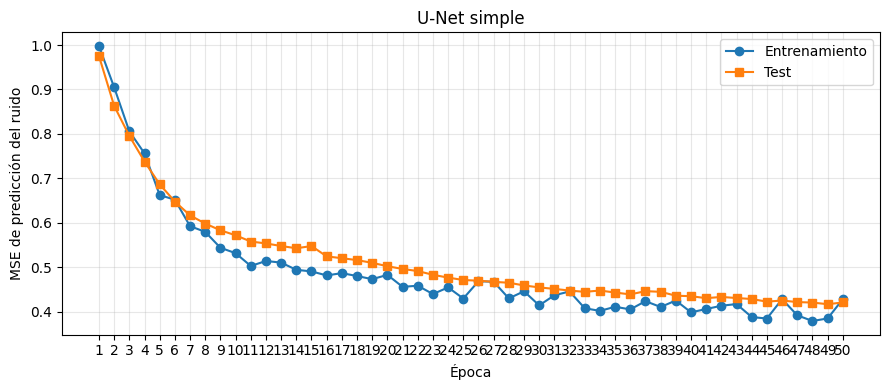

In [ ]:
rng_unet = np.random.default_rng(0)

def agregar_ruido(X, copias=1, voltear=True):
    X = np.repeat(X, copias, axis=0).copy()
    if voltear:
        cuales = rng_unet.random(len(X)) < 0.5
        X[cuales] = X[cuales, :, ::-1, :]
    s = rng_unet.choice(sigmas, size=(len(X), 1, 1, 1)).astype("float32")
    ruido = rng_unet.normal(size=X.shape).astype("float32")
    return [X + s * ruido, np.log(s).reshape(-1, 1)], ruido

entradas_test, ruido_test_u = agregar_ruido(test, copias=4, voltear=False)

n_epocas = 50
perd_train, perd_test = [], []

for epoca in range(n_epocas):
    entradas, ruido_real = agregar_ruido(entrenamiento, copias=4)
    h = unet.fit(entradas, ruido_real, epochs=1, batch_size=16, verbose=0)
    perd_train.append(h.history["loss"][0])
    perd_test.append(unet.evaluate(entradas_test, ruido_test_u, verbose=0))
    print(f"Época {epoca+1:02d}/{n_epocas} | train {perd_train[-1]:.4f} | test {perd_test[-1]:.4f}")

# Curva con un punto por época
epocas = range(1, n_epocas + 1)

plt.figure(figsize=(9, 4))
plt.plot(epocas, perd_train, "o-", label="Entrenamiento")
plt.plot(epocas, perd_test, "s-", label="Test")
plt.xticks(epocas)
plt.xlabel("Época")
plt.ylabel("MSE de predicción del ruido")
plt.title("U-Net simple")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Denosing - compración

MSE con ruido: 0.022465052
MSE CNN:       0.02233639
MSE U-Net:     0.005005618


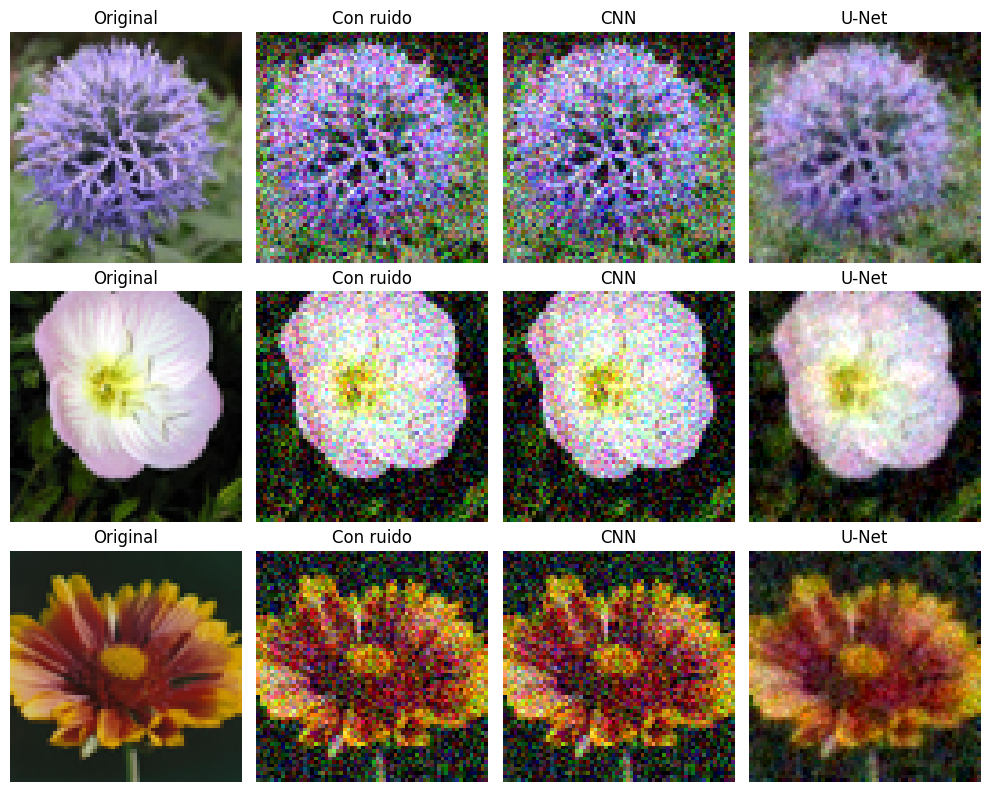

In [ ]:
s_eval = np.float32(0.15)
ruido = np.random.default_rng(7).normal(size=test.shape).astype("float32")
y_eval = test + s_eval * ruido

limpia_cnn = y_eval - s_eval * modelo.predict(y_eval, verbose=0)
log_s = np.full((len(test), 1), np.log(s_eval), dtype="float32")
limpia_unet = y_eval - s_eval * unet.predict([y_eval, log_s], verbose=0)

print("MSE con ruido:", np.mean((y_eval - test)**2))
print("MSE CNN:      ", np.mean((limpia_cnn - test)**2))
print("MSE U-Net:    ", np.mean((limpia_unet - test)**2))

fig, ejes = plt.subplots(3, 4, figsize=(10, 8))
for f in range(3):
    for eje, img, t in zip(ejes[f], [test[f], y_eval[f], limpia_cnn[f], limpia_unet[f]],
                           ["Original", "Con ruido", "CNN", "U-Net"]):
        eje.imshow(np.clip(img, 0, 1)); eje.set_title(t); eje.axis("off")
plt.tight_layout(); plt.show()

Con U_Net obtenemos un MSE de recuperación menor al de la CNN de 3 capas. Esto se debe a que tenemos un codificador-decodificador que usa toda la información de la imagen.

#### Modelo Generativo

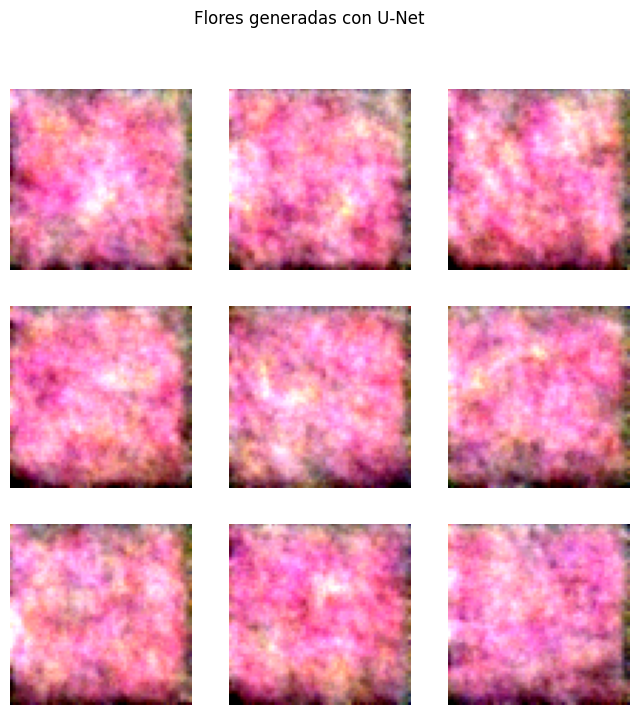

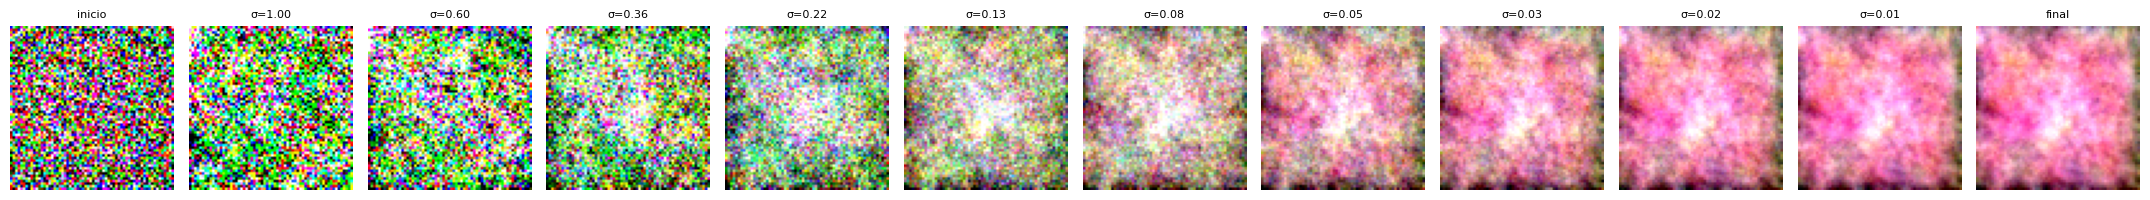

In [ ]:
def generar(red, n=9, K=100, c=2e-5, semilla=123):
    rng_g = np.random.default_rng(semilla)
    forma = (n,) + entrenamiento.shape[1:]

    # Empezamos con la flor promedio + mucho ruido
    Y = (entrenamiento.mean(axis=0) + sigmas[0] * rng_g.normal(size=forma)).astype("float32")
    evolucion = {"inicio": Y[0].copy()}

    for s in sigmas:                          # de mucho ruido a poco ruido
        h = np.float32(c * (s / sigmas[-1])**2)
        log_s = np.full((n, 1), np.log(s), dtype="float32")
        for _ in range(K):
            ruido_pred = keras.ops.convert_to_numpy(red.predict_on_batch([Y, log_s]))
            score = -ruido_pred / s
            Z = rng_g.normal(size=forma).astype("float32")
            Y = Y + h * score + np.sqrt(2 * h) * Z
        evolucion[f"σ={s:.2f}"] = Y[0].copy()

    # Limpieza final
    log_s = np.full((n, 1), np.log(sigmas[-1]), dtype="float32")
    Y = Y - sigmas[-1] * keras.ops.convert_to_numpy(red.predict_on_batch([Y, log_s]))
    evolucion["final"] = Y[0].copy()
    return Y, evolucion

generadas_unet, evolucion = generar(unet)

# Las 9 flores generadas
fig, ejes = plt.subplots(3, 3, figsize=(8, 8))
for i, eje in enumerate(ejes.flat):
    eje.imshow(np.clip(generadas_unet[i], 0, 1)); eje.axis("off")
plt.suptitle("Flores generadas con U-Net"); plt.show()

# Cómo va apareciendo la flor
fig, ejes = plt.subplots(1, len(evolucion), figsize=(1.8 * len(evolucion), 2.4))
for eje, (t, img) in zip(ejes, evolucion.items()):
    eje.imshow(np.clip(img, 0, 1)); eje.set_title(t, fontsize=8); eje.axis("off")
plt.tight_layout(); plt.show()

Las imágenes generadas ahora son más suaves, con zonas, patrones y manchas en diferentes tipos y tonos de colores, y son diferentes entre sí, y aparentemente tienen las mismas características del conjunto Oxford flowers. Las épocas se quedan cortas para llegar a resolver la flor por completo, y vemos que el coste aún no termina de minimizarse, pero el modelo funciona bastante bien.


 Es necesario recalcar que la red propuesta tiene bloques simples, pocos filtros y niveles, pues una red más estructurada requiere bastante recursos computacionales. Para nuestro caso, la red implementada con approx 100mil parámetros nos muestra que el modelo de U_Net funciona mucha mejor.